# JobGuard AI - Milestone 5: Multinomial Naive Bayes and a Cleaner Model-Selection Protocol

**Why this notebook is different from Milestone 4.** In Milestone 4 we compared two Logistic Regression versions *using the test set*. That was fine for a first experiment, but every time we look at test results to make a choice, the test set becomes slightly less "untouched". From now on:

| Data | Used for |
|---|---|
| **Model-training subset** (80% of `train.csv`) | teaching each model |
| **Validation subset** (20% of `train.csv`) | **comparing model choices** (alpha, class priors, which model is better) |
| **Test set** (`test.csv`) | **left alone** until the final comparison of all models |

**In this notebook**
1. Split `train.csv` into model-training and validation subsets
2. Train Multinomial Naive Bayes with a small number of settings and choose the best one **on validation data**
3. Train a balanced Logistic Regression on the same subsets as a fair reference
4. Compare the two on validation data
5. Retrain the selected Naive Bayes on the full `train.csv` and save it

**No test-set metrics are calculated anywhere in this notebook.** XGBoost and DistilBERT come later.

## 0. Imports and paths

In [1]:
import hashlib
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

sys.path.append("..")   # project root, so "from src..." works
from src.evaluation import calculate_metrics, plot_confusion_matrix
from src.preprocessing import create_combined_text

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../results/figures")
METRICS_DIR = Path("../results/metrics")
MODELS_DIR = Path("../models")
for folder in [FIGURES_DIR, METRICS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Same TF-IDF settings as Milestone 4
tfidf_settings = dict(lowercase=True, stop_words="english",
                      ngram_range=(1, 2), min_df=2, max_features=20000)

To prove later that we never modified the processed data files, we record a **fingerprint** (an MD5 hash) of each file now and compare it at the end. If even one character changed, the fingerprint would change.

In [2]:
def file_fingerprint(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

fingerprints_at_start = {
    "train.csv": file_fingerprint(PROCESSED_DIR / "train.csv"),
    "test.csv": file_fingerprint(PROCESSED_DIR / "test.csv"),
}
fingerprints_at_start

{'train.csv': '0a5b5a32b8d08433aa9858ac2ec5eb71',
 'test.csv': '980610d447225de4f8ef37c819b2fc45'}

## 1. Load the data

We load `train.csv` fully. For `test.csv` we read **only the number of rows** to confirm the file is there. Its text and labels are **not** stored in any variable, and we calculate **no test metrics**.

In [3]:
train_full = pd.read_csv(PROCESSED_DIR / "train.csv")
X_train_full = train_full["combined_text"]
y_train_full = train_full["fraudulent"]

test_rows = len(pd.read_csv(PROCESSED_DIR / "test.csv", usecols=["fraudulent"]))   # size only

print("train.csv shape:", train_full.shape)
print("test.csv rows (size only, reserved for the final comparison):", test_rows)

train.csv shape: (12852, 5)
test.csv rows (size only, reserved for the final comparison): 3214


## 2. Split `train.csv` into model-training and validation subsets

- **Model-training subset:** used to teach the model.
- **Validation subset:** used to compare model choices (for example, which alpha is best). The model never learns from it.
- **Test set:** kept untouched until later, so it stays an honest final check.

We use a **stratified** 80/20 split again, because only about 4-5% of postings are fraudulent. `random_state=42` makes the split repeatable.

In [4]:
(X_model_train, X_validation,
 y_model_train, y_validation) = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full,
)

print(f"Model-training rows: {len(X_model_train):,}   fraudulent: {int(y_model_train.sum())} "
      f"({y_model_train.mean() * 100:.2f}%)")
print(f"Validation rows:     {len(X_validation):,}   fraudulent: {int(y_validation.sum())} "
      f"({y_validation.mean() * 100:.2f}%)")

shared_texts = set(X_model_train) & set(X_validation)
print("Identical combined_text values in both subsets:", len(shared_texts))
assert len(shared_texts) == 0

Model-training rows: 10,281   fraudulent: 459 (4.46%)
Validation rows:     2,571   fraudulent: 115 (4.47%)
Identical combined_text values in both subsets: 0


There is no text overlap, because `train.csv` already contains only unique texts (Milestone 3). So validation results reflect text the model has not seen.

## 3. TF-IDF features

Same TF-IDF as Milestone 4 (see that notebook for the explanation). The vectorizer is **fitted only on the model-training subset**. The validation text is only **transformed** using what was learned from the training subset. Fitting on validation text would leak information and make validation scores too optimistic.

In [5]:
tfidf = TfidfVectorizer(**tfidf_settings)

X_model_train_tfidf = tfidf.fit_transform(X_model_train)   # learn vocabulary from the training subset only
X_validation_tfidf = tfidf.transform(X_validation)         # transform only

print("Model-training TF-IDF matrix shape:", X_model_train_tfidf.shape)
print("Validation TF-IDF matrix shape:    ", X_validation_tfidf.shape)
print("Vocabulary size:                   ", len(tfidf.get_feature_names_out()))

Model-training TF-IDF matrix shape: (10281, 20000)
Validation TF-IDF matrix shape:     (2571, 20000)
Vocabulary size:                    20000


## 4. What is Multinomial Naive Bayes?

**Naive Bayes** is a classic algorithm for text classification. It works with **probabilities**:

1. During training it looks at every word (or phrase) and measures **how strongly it is associated with each class**. For example, how often does "data entry" show up in fraudulent postings compared with legitimate ones?
2. For a new posting it combines the evidence from all of its words and calculates how likely the posting is to be fraudulent or legitimate.
3. It predicts the more likely class.

**Why "naive"?** It assumes that, once we know the class, each word contributes **independently** of the other words. That is not really true (words like "bank" and "account" travel together), so it is a **simplifying assumption**. Even so, Naive Bayes is **very fast** and often works **surprisingly well on text**.

**"Multinomial"** is the version designed for word counts and word-weight features such as TF-IDF.

**Why compare it with Logistic Regression?** Both are traditional, lightweight text models. Logistic Regression *learns weights* that separate the two classes directly, while Naive Bayes just *counts how words are distributed in each class*. Comparing them shows how much a more careful training method helps.

## 5. Baseline Multinomial Naive Bayes (`alpha=1.0`)

We train on the model-training subset only and evaluate on the **validation** subset only.

In [6]:
nb_baseline = MultinomialNB(alpha=1.0)
nb_baseline.fit(X_model_train_tfidf, y_model_train)

baseline_pred = nb_baseline.predict(X_validation_tfidf)
baseline_metrics = calculate_metrics(y_validation, baseline_pred)

print("Multinomial Naive Bayes, alpha=1.0 (VALIDATION results)")
print(f"  Accuracy:        {baseline_metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {baseline_metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {baseline_metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {baseline_metrics['Fraud F1']:.4f}")
print()
print(f"  True Negatives: {baseline_metrics['True Negatives']}   False Positives: {baseline_metrics['False Positives']}")
print(f"  False Negatives: {baseline_metrics['False Negatives']}   True Positives: {baseline_metrics['True Positives']}")

Multinomial Naive Bayes, alpha=1.0 (VALIDATION results)
  Accuracy:        0.9560
  Fraud precision: 0.5385
  Fraud recall:    0.1217
  Fraud F1-score:  0.1986

  True Negatives: 2444   False Positives: 12
  False Negatives: 101   True Positives: 14


In [7]:
print(classification_report(y_validation, baseline_pred,
                            target_names=["Legitimate (0)", "Fraudulent (1)"], digits=3, zero_division=0))

                precision    recall  f1-score   support

Legitimate (0)      0.960     0.995     0.977      2456
Fraudulent (1)      0.538     0.122     0.199       115

      accuracy                          0.956      2571
     macro avg      0.749     0.558     0.588      2571
  weighted avg      0.941     0.956     0.943      2571



**Reading the baseline:** accuracy looks high, but accuracy alone is misleading here because most validation postings are legitimate. Look at **fraud recall**: with `alpha=1.0` the model catches only a small share of the real scams. Let's see whether less smoothing helps.

## 6. Comparing a few `alpha` values

**Smoothing (`alpha`).** Imagine a word that never appeared in a fraudulent training posting. Without smoothing, the model would think that word makes fraud *impossible*, which is too extreme just because we did not happen to see it. **Smoothing** adds a small pretend count to every word so no probability is exactly zero or extreme.

- **Small alpha** (e.g. 0.1): trusts the training counts more, so rare words can have a bigger effect.
- **Large alpha** (e.g. 1.0): smooths more, so rare words matter less.

We try only **three** easy-to-explain values: 0.1, 0.5 and 1.0, and compare them on the **validation** subset.

In [8]:
def evaluate_naive_bayes(alpha, fit_prior):
    model = MultinomialNB(alpha=alpha, fit_prior=fit_prior)
    model.fit(X_model_train_tfidf, y_model_train)            # learn from the training subset
    predictions = model.predict(X_validation_tfidf)          # judge on validation
    return {"alpha": alpha, "fit_prior": fit_prior, **calculate_metrics(y_validation, predictions)}

alpha_values = [0.1, 0.5, 1.0]
alpha_results = pd.DataFrame([evaluate_naive_bayes(alpha, fit_prior=True) for alpha in alpha_values])

show_columns = ["alpha", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
alpha_results[show_columns].round(4)

,alpha,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,0.1,0.9798,0.8987,0.6174,0.7320
1,0.5,0.9603,0.6512,0.2435,0.3544
2,1.0,0.9560,0.5385,0.1217,0.1986


## 7. Class imbalance and Naive Bayes

`MultinomialNB` has **no `class_weight` option** like Logistic Regression. It does have something related: **class priors**, the model's starting belief about how common each class is *before* it reads a posting.

- `fit_prior=True` (default): the prior is learned from the training data. Since about 95% of postings are legitimate, the model starts out strongly expecting "legitimate", so it needs a lot of evidence before it says "fraud".
- `fit_prior=False`: the model starts with **equal** belief in both classes (50/50), so fraud needs less evidence. This is a supported, simple option, and in spirit it is similar to class weighting.

It is **not guaranteed** to help; it usually trades precision for recall. We therefore test just this one extra variant, with the same three alpha values, and let the **validation** results decide. (We deliberately do not hand-pick custom `class_prior` numbers, because that would be guesswork.)

In [9]:
uniform_prior_results = pd.DataFrame([evaluate_naive_bayes(alpha, fit_prior=False) for alpha in alpha_values])
uniform_prior_results[show_columns].round(4)

,alpha,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,0.1,0.9273,0.3741,0.9304,0.5337
1,0.5,0.9436,0.4148,0.6348,0.5017
2,1.0,0.9401,0.3107,0.2783,0.2936


### All Naive Bayes configurations (validation)

We now have six configurations: three alpha values, each with the default prior (`fit_prior=True`) and the equal prior (`fit_prior=False`). We choose the one with the best **fraud F1** on validation, and look at the precision/recall balance behind it. Remember that the validation subset contains only a modest number of fraudulent postings, so small differences between configurations are noisy.

In [10]:
nb_results = pd.concat([alpha_results, uniform_prior_results], ignore_index=True)
nb_results["Configuration"] = ("alpha=" + nb_results["alpha"].astype(str)
                               + ", fit_prior=" + nb_results["fit_prior"].astype(str))

nb_results[["Configuration", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]].round(4)

,Configuration,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,"alpha=0.1, fit_prior=True",0.9798,0.8987,0.6174,0.7320
1,"alpha=0.5, fit_prior=True",0.9603,0.6512,0.2435,0.3544
2,"alpha=1.0, fit_prior=True",0.9560,0.5385,0.1217,0.1986
3,"alpha=0.1, fit_prior=False",0.9273,0.3741,0.9304,0.5337
4,"alpha=0.5, fit_prior=False",0.9436,0.4148,0.6348,0.5017
5,"alpha=1.0, fit_prior=False",0.9401,0.3107,0.2783,0.2936


In [11]:
best_nb = nb_results.loc[nb_results["Fraud F1"].idxmax()]
selected_alpha = float(best_nb["alpha"])
selected_fit_prior = bool(best_nb["fit_prior"])

print("Selected Naive Bayes configuration:", best_nb["Configuration"])
print(f"  Validation fraud F1 {best_nb['Fraud F1']:.4f} | precision {best_nb['Fraud Precision']:.4f} "
      f"| recall {best_nb['Fraud Recall']:.4f}")

Selected Naive Bayes configuration: alpha=0.1, fit_prior=True
  Validation fraud F1 0.7320 | precision 0.8987 | recall 0.6174


### What the alpha and prior comparison shows

- **With the default prior, a smaller alpha is clearly better.** Less smoothing lets rare but distinctive words matter more. With heavy smoothing (alpha=1.0) the model leans on the "most postings are legitimate" prior and misses most scams, so fraud recall falls sharply.
- **The equal prior (`fit_prior=False`) boosts fraud recall but hurts fraud precision**, so it creates many more false alarms. In these runs it did not give a better fraud F1 than the default prior.
- We **select the configuration with the best validation fraud F1**, as printed above. It is a good example of the precision/recall trade-off: high precision (few false alarms) with moderate recall.

**Two honest caveats.** (1) The selected alpha is the **smallest value we tried**, and F1 kept improving as alpha got smaller, so an even smaller alpha might do better. We stopped at three values on purpose, to keep the experiment simple and explainable. (2) The validation subset has only a modest number of fraudulent postings, so small score differences between configurations are not very reliable.

## 8. Balanced Logistic Regression: validation reference

To compare fairly, we train the balanced Logistic Regression again, this time on the **same model-training subset**, with the **same TF-IDF features**, and evaluate it on the **same validation subset**. This is not a new model; it is an apples-to-apples reference. (Its Milestone 4 numbers came from a different evaluation setup, so we do not compare against those.)

In [12]:
logistic_balanced = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
logistic_balanced.fit(X_model_train_tfidf, y_model_train)

logistic_pred = logistic_balanced.predict(X_validation_tfidf)
logistic_metrics = calculate_metrics(y_validation, logistic_pred)

print("Balanced Logistic Regression (VALIDATION results)")
print(f"  Accuracy:        {logistic_metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {logistic_metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {logistic_metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {logistic_metrics['Fraud F1']:.4f}")

Balanced Logistic Regression (VALIDATION results)
  Accuracy:        0.9701
  Fraud precision: 0.6118
  Fraud recall:    0.9043
  Fraud F1-score:  0.7298


## 9. Naive Bayes vs Logistic Regression (validation)

First we retrain the **selected** Naive Bayes configuration so we have its validation predictions (this is the same training as in Section 7), then build the comparison table.

In [13]:
nb_selected = MultinomialNB(alpha=selected_alpha, fit_prior=selected_fit_prior)
nb_selected.fit(X_model_train_tfidf, y_model_train)

nb_pred = nb_selected.predict(X_validation_tfidf)
nb_metrics = calculate_metrics(y_validation, nb_pred)

comparison = pd.DataFrame([
    {"Model": "Logistic Regression (Balanced)", "Configuration": "class_weight=balanced", **logistic_metrics},
    {"Model": "Multinomial Naive Bayes", "Configuration": f"alpha={selected_alpha}, fit_prior={selected_fit_prior}", **nb_metrics},
])

comparison_columns = ["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
comparison[comparison_columns].round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Logistic Regression (Balanced),0.9701,0.6118,0.9043,0.7298
1,Multinomial Naive Bayes,0.9798,0.8987,0.6174,0.7320


In [14]:
lr_name, nb_name = "Balanced Logistic Regression", "Naive Bayes"

def better(metric, higher_is_better=True):
    lr_value, nb_value = logistic_metrics[metric], nb_metrics[metric]
    if lr_value == nb_value:
        return "tie"
    if higher_is_better:
        return lr_name if lr_value > nb_value else nb_name
    return lr_name if lr_value < nb_value else nb_name

print(f"Catches more fraud (higher recall):  {better('Fraud Recall')}  "
      f"(missed scams: LR {logistic_metrics['False Negatives']}, NB {nb_metrics['False Negatives']})")
print(f"Fewer false alarms (fewer FP):       {better('False Positives', higher_is_better=False)}  "
      f"(false alarms: LR {logistic_metrics['False Positives']}, NB {nb_metrics['False Positives']})")
print(f"Higher fraud precision:              {better('Fraud Precision')}")
print(f"Higher fraud F1:                     {better('Fraud F1')}")

Catches more fraud (higher recall):  Balanced Logistic Regression  (missed scams: LR 11, NB 44)
Fewer false alarms (fewer FP):       Naive Bayes  (false alarms: LR 66, NB 8)
Higher fraud precision:              Naive Bayes
Higher fraud F1:                     Naive Bayes


### How the two traditional models compare (validation only)

- **Fraud F1 is almost the same** for the two models. The gap is tiny, and with so few fraudulent validation postings it is well within what could change from a different random split. We should **not** conclude that one is better on F1.
- **They behave very differently:**
  - **Balanced Logistic Regression catches more fraud** (higher recall, fewer missed scams) but raises **more false alarms** (lower precision).
  - **Naive Bayes raises far fewer false alarms** (higher precision) but **misses more scams** (lower recall).
- Naive Bayes also has higher accuracy, but as we know, accuracy is not a good basis for judging fraud detection here.

So the choice depends on what JobGuard values most: catching as many scams as possible, or avoiding false warnings about real jobs. **We are not declaring an overall winner.** XGBoost and DistilBERT are still to come, and the final comparison of all models will use the untouched test set.

## 10. Confusion matrix: selected Naive Bayes (validation)

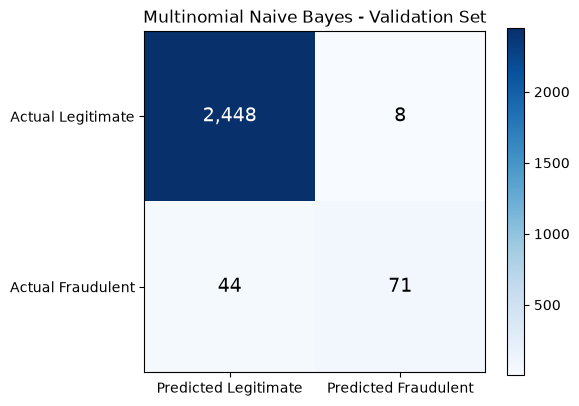

True Negatives : 2448
False Positives: 8
False Negatives: 44
True Positives : 71


In [15]:
plot_confusion_matrix(y_validation, nb_pred,
                      "Multinomial Naive Bayes - Validation Set",
                      FIGURES_DIR / "naive_bayes_validation_confusion_matrix.png")

print("True Negatives :", nb_metrics["True Negatives"])
print("False Positives:", nb_metrics["False Positives"])
print("False Negatives:", nb_metrics["False Negatives"])
print("True Positives :", nb_metrics["True Positives"])

## 11. Comparison chart (validation)

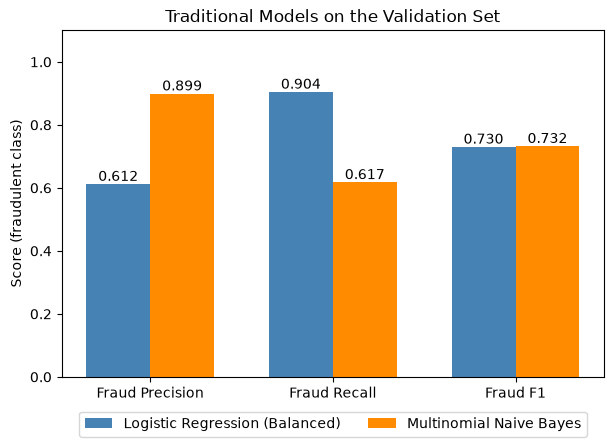

In [16]:
chart_metrics = ["Fraud Precision", "Fraud Recall", "Fraud F1"]
positions = np.arange(len(chart_metrics))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
bars_lr = ax.bar(positions - bar_width / 2, comparison.loc[0, chart_metrics].astype(float),
                 bar_width, label=comparison.loc[0, "Model"], color="steelblue")
bars_nb = ax.bar(positions + bar_width / 2, comparison.loc[1, chart_metrics].astype(float),
                 bar_width, label=comparison.loc[1, "Model"], color="darkorange")
ax.bar_label(bars_lr, fmt="%.3f")
ax.bar_label(bars_nb, fmt="%.3f")

ax.set_xticks(positions, labels=chart_metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score (fraudulent class)")
ax.set_title("Traditional Models on the Validation Set")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
fig.savefig(FIGURES_DIR / "traditional_models_validation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Save the metrics

- `naive_bayes_validation_results.csv`: every Naive Bayes configuration we tried.
- `traditional_models_validation_comparison.csv`: balanced Logistic Regression vs the selected Naive Bayes.

All values come from the calculations above.

In [17]:
nb_results_to_save = nb_results[["Configuration", "alpha", "fit_prior", "Accuracy", "Fraud Precision",
                                 "Fraud Recall", "Fraud F1", "True Negatives", "False Positives",
                                 "False Negatives", "True Positives"]]
nb_results_to_save.to_csv(METRICS_DIR / "naive_bayes_validation_results.csv", index=False)
comparison.to_csv(METRICS_DIR / "traditional_models_validation_comparison.csv", index=False)

pd.read_csv(METRICS_DIR / "traditional_models_validation_comparison.csv")

,Model,Configuration,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression (Balanced),class_weight=balanced,0.970051,0.611765,0.904348,0.729825,2390,66,11,104
1,Multinomial Naive Bayes,"alpha=0.1, fit_prior=True",0.979774,0.898734,0.617391,0.731959,2448,8,44,71


## 13. Retrain the selected Naive Bayes on the full `train.csv` and save it

The settings are now **decided** using validation data. For the final saved model we want to learn from as much training data as possible, so we retrain the chosen configuration on **all of `train.csv`** (model-training + validation subsets). The test set is not included.

We use one scikit-learn **Pipeline** (TF-IDF + Multinomial Naive Bayes), so it can accept raw `combined_text`. Because this pipeline has now seen the validation rows, its validation scores would be meaningless, so we do **not** evaluate it on validation or test here.

In [18]:
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_settings)),
    ("naive_bayes", MultinomialNB(alpha=selected_alpha, fit_prior=selected_fit_prior)),
])
nb_pipeline.fit(X_train_full, y_train_full)   # all of train.csv, no test data

PIPELINE_PATH = MODELS_DIR / "naive_bayes_pipeline.joblib"
joblib.dump(nb_pipeline, PIPELINE_PATH)
print("Saved:", PIPELINE_PATH, f"({PIPELINE_PATH.stat().st_size / 1_000_000:.1f} MB)")
print("Trained on", len(X_train_full), "rows with alpha =", selected_alpha, "and fit_prior =", selected_fit_prior)

Saved: ../models/naive_bayes_pipeline.joblib (1.5 MB)
Trained on 12852 rows with alpha = 0.1 and fit_prior = True


In [19]:
reloaded_pipeline = joblib.load(PIPELINE_PATH)

raw_example = "TITLE: Barista\nCOMPANY PROFILE: A friendly local cafe.\nDESCRIPTION: Make coffee and serve customers.\nREQUIREMENTS: \nBENEFITS: "
print("Prediction from a raw string:", reloaded_pipeline.predict([raw_example]).tolist(),
      "| probabilities [legitimate, fraud]:", reloaded_pipeline.predict_proba([raw_example])[0].round(3).tolist())

Prediction from a raw string: [0] | probabilities [legitimate, fraud]: [0.982, 0.018]


## 14. Sanity-check with demonstration examples

> **Hand-written demonstration examples only. They are not test data and are not used for any decision.** They show that the saved pipeline accepts raw text and returns a prediction and a probability.

These are the same three examples used in the Logistic Regression notebook. (Naive Bayes probabilities tend to be more extreme than Logistic Regression ones, so read them as rough scores, not precise confidence levels.)

In [20]:
demo_examples = pd.DataFrame([
    {
        "name": "Professional posting (demo)",
        "title": "Software Engineer",
        "company_profile": "Northwind Analytics is a data company serving hospitals and universities. "
                           "We build tools that help researchers understand their data.",
        "description": "We are looking for a software engineer to join our platform team. You will design, "
                       "build and test backend services in Python, review code with teammates, and "
                       "participate in on-call rotation.",
        "requirements": "Bachelor's degree in computer science or equivalent experience. 3 years of Python "
                        "and SQL. Experience with automated testing and version control.",
        "benefits": "Health, dental and vision insurance, 401(k) match, paid vacation.",
    },
    {
        "name": "Suspicious posting (demo)",
        "title": "Work From Home - Earn $5000 Weekly!!!",
        "company_profile": "",
        "description": "No experience needed! Earn thousands every week from home. Limited spots. "
                       "Send your full name, address, date of birth and bank account details to "
                       "start immediately. A small registration fee is required.",
        "requirements": "Must have a bank account and be able to pay the registration fee.",
        "benefits": "",
    },
    {
        "name": "Very short posting (demo)",
        "title": "Data Entry Clerk",
        "company_profile": "",
        "description": "Data entry. Work from home. Apply now.",
        "requirements": "",
        "benefits": "",
    },
])

demo_text = create_combined_text(demo_examples)
demo_pred = reloaded_pipeline.predict(demo_text)
demo_prob = reloaded_pipeline.predict_proba(demo_text)[:, 1]

for name, prediction, probability in zip(demo_examples["name"], demo_pred, demo_prob):
    label = "Potentially Fraudulent" if prediction == 1 else "Likely Legitimate"
    print(f"{name:32s} -> {label:24s} (fraud probability: {probability:.3f})")

Professional posting (demo)      -> Likely Legitimate        (fraud probability: 0.004)
Suspicious posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.506)
Very short posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.907)


## 15. Validation checks

Each `assert` stops the notebook with an error if a check fails.

In [21]:
# 1. The processed data files are byte-for-byte unchanged (test.csv was never modified)
fingerprints_at_end = {
    "train.csv": file_fingerprint(PROCESSED_DIR / "train.csv"),
    "test.csv": file_fingerprint(PROCESSED_DIR / "test.csv"),
}
assert fingerprints_at_end == fingerprints_at_start
print("PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)")

# 2. Test data never entered this notebook's model code: only its row count was read
assert not any(name in globals() for name in ("X_test", "y_test", "test_df", "test"))
print("PASS: no test text or labels were loaded into memory (only its row count)")

# 3. TF-IDF was fitted only on the internal training subset
refit_on_subset_only = TfidfVectorizer(**tfidf_settings).fit(X_model_train)
assert list(refit_on_subset_only.get_feature_names_out()) == list(tfidf.get_feature_names_out())
print("PASS: TF-IDF vocabulary equals the vocabulary learned from the model-training subset alone")

# 4. Validation text was only transformed
assert X_validation_tfidf.shape == (len(X_validation), X_model_train_tfidf.shape[1])
print("PASS: validation matrix has the training vocabulary's columns (transformed, not fitted)")

# 5. No text overlap between internal train and validation
assert len(set(X_model_train) & set(X_validation)) == 0
assert len(X_model_train) + len(X_validation) == len(train_full)
print("PASS: no combined_text overlap between model-training and validation subsets")

# 6. Final pipeline: fitted on the full train.csv only, after selection
full_train_vocabulary = TfidfVectorizer(**tfidf_settings).fit(X_train_full).get_feature_names_out()
assert list(reloaded_pipeline.named_steps["tfidf"].get_feature_names_out()) == list(full_train_vocabulary)
nb_step = reloaded_pipeline.named_steps["naive_bayes"]
assert nb_step.alpha == selected_alpha and nb_step.fit_prior == selected_fit_prior
print("PASS: saved pipeline was fitted on the full train.csv with the validation-selected settings")

# 7. Saved pipeline reloads and predicts
assert reloaded_pipeline.predict(X_train_full[:20]).shape == (20,)
print("PASS: saved pipeline reloads and predicts from raw text")

# 8. Metrics files match the notebook results
saved_nb = pd.read_csv(METRICS_DIR / "naive_bayes_validation_results.csv")
saved_comparison = pd.read_csv(METRICS_DIR / "traditional_models_validation_comparison.csv")
metric_columns = ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
assert np.allclose(saved_nb[metric_columns].values, nb_results[metric_columns].astype(float).values)
assert np.allclose(saved_comparison[metric_columns].values, comparison[metric_columns].astype(float).values)
print("PASS: both metrics CSV files match the notebook results")

# 9. Figures exist and are non-empty
for figure_name in ["naive_bayes_validation_confusion_matrix.png", "traditional_models_validation_comparison.png"]:
    assert (FIGURES_DIR / figure_name).stat().st_size > 0
print("PASS: both figure files were saved")

PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)
PASS: no test text or labels were loaded into memory (only its row count)


PASS: TF-IDF vocabulary equals the vocabulary learned from the model-training subset alone
PASS: validation matrix has the training vocabulary's columns (transformed, not fitted)
PASS: no combined_text overlap between model-training and validation subsets


PASS: saved pipeline was fitted on the full train.csv with the validation-selected settings
PASS: saved pipeline reloads and predicts from raw text
PASS: both metrics CSV files match the notebook results
PASS: both figure files were saved


## 16. Summary (numbers printed by code)

In [22]:
print("INTERNAL SPLIT")
print(f"  Model-training rows: {len(X_model_train):,}  (fraudulent: {int(y_model_train.sum())})")
print(f"  Validation rows:     {len(X_validation):,}  (fraudulent: {int(y_validation.sum())})")
print()
print("NAIVE BAYES CONFIGURATIONS (validation)")
print(nb_results[["Configuration", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]].round(4).to_string(index=False))
print()
print("Selected Naive Bayes:", best_nb["Configuration"])
print()
print("TRADITIONAL MODELS (validation)")
print(comparison[comparison_columns].round(4).to_string(index=False))
print()
print("TEST SET: only its size was read (", test_rows, "rows). No test metrics were calculated.")

INTERNAL SPLIT
  Model-training rows: 10,281  (fraudulent: 459)
  Validation rows:     2,571  (fraudulent: 115)

NAIVE BAYES CONFIGURATIONS (validation)
             Configuration  Accuracy  Fraud Precision  Fraud Recall  Fraud F1
 alpha=0.1, fit_prior=True    0.9798           0.8987        0.6174    0.7320
 alpha=0.5, fit_prior=True    0.9603           0.6512        0.2435    0.3544
 alpha=1.0, fit_prior=True    0.9560           0.5385        0.1217    0.1986
alpha=0.1, fit_prior=False    0.9273           0.3741        0.9304    0.5337
alpha=0.5, fit_prior=False    0.9436           0.4148        0.6348    0.5017
alpha=1.0, fit_prior=False    0.9401           0.3107        0.2783    0.2936

Selected Naive Bayes: alpha=0.1, fit_prior=True

TRADITIONAL MODELS (validation)
                         Model  Accuracy  Fraud Precision  Fraud Recall  Fraud F1
Logistic Regression (Balanced)    0.9701           0.6118        0.9043    0.7298
       Multinomial Naive Bayes    0.9798           0.89

### What we learned

- A **validation subset** lets us make choices (alpha, priors, which model is better) without using the test set, so the test set can still give an honest final check.
- **Naive Bayes** counts how words are spread across the two classes and combines that evidence with probabilities. **Logistic Regression** instead learns a weight for each word that directly separates the classes.
- Choosing **alpha** and the **class prior** changes how many scams are caught versus how many false alarms appear.
- Neither model is declared the winner yet. XGBoost and DistilBERT are still to come, and the final comparison of all models will use the untouched test set.

**Next milestone:** train **XGBoost** as the first advanced model, using the same validation-based methodology.